
# ELE680 – Deep Neural Networks
## Group 2: Long-Horizon Time Series Forecasting
### 06 – LSTM Model

**University:** University of Stavanger (UiS)  
**Course:** ELE680 – Deep Neural Networks  
**Group:** 2  
**Dataset:** ETTh1 (Electricity Transformer Temperature)  
**Date:** October 21, 2026

---

## 1. Objective

The objective of this notebook is to implement and evaluate a Long Short-Term Memory (LSTM) neural network for multivariate long-horizon time series forecasting.

The main research question is:

**Does increased model complexity improve long-horizon forecasting performance?**

The LSTM model will be compared with Persistence, DLinear, and Transformer models using the same ETTh1 dataset, preprocessing methodology, and evaluation metrics.

## 2. Experimental Setup

| Parameter | Configuration |
|---|---|
| Dataset | ETTh1 (Hourly) |
| Input sequence length | 96 hours |
| Input features | 7 |
| Prediction target | Oil Temperature (OT) |
| Target feature index | 6 |
| Prediction horizons | 96, 336, 720 hours |
| Architecture | LSTM encoder + Linear output layer |
| Hidden size | 64 |
| LSTM layers | 2 |
| Dropout | 0.1 |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 32 |
| Maximum epochs | 30 |
| Early stopping patience | 5 |
| Loss function | Mean Squared Error (MSE) |
| Evaluation metrics | MSE and MAE |
| Framework | PyTorch |
| Hardware | NVIDIA Tesla P100 GPU |

## 3. Methodology

The LSTM model uses a **direct multi-step forecasting strategy**.

1. The model receives 96 hours of historical observations containing seven input features.
2. Two stacked LSTM layers learn temporal dependencies within the input sequence.
3. The final LSTM output represents the learned historical information.
4. A fully connected linear layer maps this representation directly to the required forecasting horizon.
5. Separate models are trained and evaluated for 96-hour, 336-hour, and 720-hour predictions.

The existing preprocessed datasets are reused to maintain consistency with the Persistence and DLinear experiments.

## 4. Expected Outputs

This notebook will produce:

- Trained LSTM models for all three prediction horizons.
- Training and validation loss curves.
- Validation and test MSE and MAE.
- Forecast versus actual value visualizations.
- Training time and model parameter counts.
- Saved model checkpoints and experimental results.

These outputs will support the final comparison of forecasting accuracy, computational cost, and model complexity across all four forecasting approaches.


In [1]:

import sys
import torch
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nWorking directory:", Path.cwd())

data_files = [
    "ETTh1_preprocessed.pt",
    "ETTh1_336h_preprocessed.pt",
    "ETTh1_720h_preprocessed.pt"
]

for filename in data_files:
    path = Path("processed_data") / filename
    print(f"{filename}: {'Found' if path.exists() else 'MISSING'}")


Python version: 3.12.15
PyTorch version: 2.5.1+cu118
CUDA available: True
GPU: Tesla P100-PCIE-12GB

Working directory: /mnt/beegfs/home/diraj5758/ELE680_Group2
ETTh1_preprocessed.pt: Found
ETTh1_336h_preprocessed.pt: Found
ETTh1_720h_preprocessed.pt: Found


In [2]:

# Step 2: Load and inspect preprocessed datasets

dataset_paths = {
    96: "processed_data/ETTh1_preprocessed.pt",
    336: "processed_data/ETTh1_336h_preprocessed.pt",
    720: "processed_data/ETTh1_720h_preprocessed.pt"
}

for horizon, path in dataset_paths.items():

    print(f"\n===== {horizon}-Hour Forecasting =====")

    data = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print("Saved keys:", list(data.keys()))

    for key, value in data.items():
        if isinstance(value, torch.Tensor):
            print(f"{key}: {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")



===== 96-Hour Forecasting =====
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train: (8449, 96, 7)
y_train: (8449, 96)
X_val: (2785, 96, 7)
y_val: (2785, 96)
X_test: (2785, 96, 7)
y_test: (2785, 96)
feature_cols: list
target_index: int
input_len: int
pred_len: int
ot_mean: float
ot_std: float

===== 336-Hour Forecasting =====
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train: (8209, 96, 7)
y_train: (8209, 336)
X_val: (2545, 96, 7)
y_val: (2545, 336)
X_test: (2545, 96, 7)
y_test: (2545, 336)
feature_cols: list
target_index: int
input_len: int
pred_len: int
ot_mean: float
ot_std: float

===== 720-Hour Forecasting =====
Saved keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train

In [3]:

import torch.nn as nn

class LSTMForecaster(nn.Module):
    def __init__(
        self,
        input_size=7,
        hidden_size=64,
        num_layers=2,
        dropout=0.1,
        pred_len=96
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, pred_len)

    def forward(self, x):
        # x shape: (batch_size, 96, 7)
        lstm_out, _ = self.lstm(x)

        # Final time step representation
        last_hidden = lstm_out[:, -1, :]

        # Predict all future time steps directly
        predictions = self.fc(last_hidden)

        return predictions


In [4]:

# Step 4: Initialize and verify the LSTM model

# Model configuration
INPUT_SIZE = 7
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.1
PRED_LEN = 96

# Select device
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Initialize LSTM model
model = LSTMForecaster(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    pred_len=PRED_LEN
).to(device)

# Display model architecture
print("LSTM Model Architecture:")
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {total_params:,}")

# Test forward pass with dummy input
dummy_input = torch.randn(
    32, 96, 7,
    device=device
)

model.eval()

with torch.no_grad():
    dummy_output = model(dummy_input)

print("\nInput shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))
print("Device:", device)

# Verify output dimensions
assert dummy_output.shape == (32, 96), \
    "Unexpected output shape!"

print("\nForward pass successful!")


LSTM Model Architecture:
LSTMForecaster(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=96, bias=True)
)

Trainable parameters: 58,208

Input shape: (32, 96, 7)
Output shape: (32, 96)
Device: cuda:0

Forward pass successful!


In [5]:

from torch.utils.data import TensorDataset, DataLoader

# Load the existing 96-hour preprocessed dataset
data_96 = torch.load(
    "processed_data/ETTh1_preprocessed.pt",
    map_location="cpu",
    weights_only=True
)

# Extract tensors
X_train = data_96["X_train"]
y_train = data_96["y_train"]

X_val = data_96["X_val"]
y_val = data_96["y_val"]

X_test = data_96["X_test"]
y_test = data_96["y_test"]

# Verify metadata
print("Input length:", data_96["input_len"])
print("Prediction length:", data_96["pred_len"])
print("Target index:", data_96["target_index"])

assert data_96["input_len"] == 96
assert data_96["pred_len"] == 96
assert data_96["target_index"] == 6

# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Verify one batch
batch_X, batch_y = next(iter(train_loader))

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nBatch input shape:", tuple(batch_X.shape))
print("Batch target shape:", tuple(batch_y.shape))

print("\nDataLoaders created successfully!")


Input length: 96
Prediction length: 96
Target index: 6

Training samples: 8449
Validation samples: 2785
Test samples: 2785

Batch input shape: (32, 96, 7)
Batch target shape: (32, 96)

DataLoaders created successfully!


In [6]:

import torch.optim as optim
import random
import numpy as np

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training hyperparameters
LEARNING_RATE = 0.001
MAX_EPOCHS = 30
PATIENCE = 5

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Early stopping variables
best_val_loss = float("inf")
patience_counter = 0
best_epoch = 0

print("Training Configuration")
print("----------------------")
print("Model: LSTM")
print("Prediction horizon:", PRED_LEN)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Random seed:", SEED)
print("Device:", device)


Training Configuration
----------------------
Model: LSTM
Prediction horizon: 96
Batch size: 32
Learning rate: 0.001
Maximum epochs: 30
Early stopping patience: 5
Loss function: MSELoss()
Optimizer: Adam
Random seed: 42
Device: cuda:0


In [7]:

import time
from pathlib import Path

# Reinitialize model AFTER setting the random seed
model = LSTMForecaster(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    pred_len=PRED_LEN
).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Reset early stopping variables
best_val_loss = float("inf")
patience_counter = 0
best_epoch = 0

train_losses = []
val_losses = []

# Create checkpoint directory
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "LSTM_96h_best.pt"

# Start training timer
if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

for epoch in range(MAX_EPOCHS):

    # ----- Training -----
    model.train()
    train_loss_sum = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_X)

        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * batch_X.size(0)

    avg_train_loss = train_loss_sum / len(train_dataset)

    # ----- Validation -----
    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_X)

            loss = criterion(predictions, batch_y)

            val_loss_sum += loss.item() * batch_X.size(0)

    avg_val_loss = val_loss_sum / len(val_dataset)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {avg_train_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f}",
        flush=True
    )

    # ----- Early Stopping -----
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Measure elapsed training time
if device.type == "cuda":
    torch.cuda.synchronize()

training_time = time.perf_counter() - start_time

# Restore best model weights
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

print("\n===== LSTM Training Summary =====")
print(f"Best epoch: {best_epoch}")
print(f"Best validation MSE: {best_val_loss:.6f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Checkpoint saved: {checkpoint_path}")

Epoch 01/30 | Train MSE: 0.259879 | Val MSE: 0.276028
Epoch 02/30 | Train MSE: 0.159377 | Val MSE: 0.281826
Epoch 03/30 | Train MSE: 0.150593 | Val MSE: 0.314271
Epoch 04/30 | Train MSE: 0.137280 | Val MSE: 0.398149
Epoch 05/30 | Train MSE: 0.125886 | Val MSE: 0.452081
Epoch 06/30 | Train MSE: 0.124141 | Val MSE: 0.447701

Early stopping triggered.

===== LSTM Training Summary =====
Best epoch: 1
Best validation MSE: 0.276028
Training time: 11.54 seconds
Checkpoint saved: checkpoints/LSTM_96h_best.pt


In [8]:

# Step 8: Evaluate LSTM on the test dataset

model.eval()

test_mse_sum = 0.0
test_mae_sum = 0.0

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        predictions = model(batch_X)

        # Sum errors over all predicted values
        test_mse_sum += torch.sum(
            (predictions - batch_y) ** 2
        ).item()

        test_mae_sum += torch.sum(
            torch.abs(predictions - batch_y)
        ).item()

# Total number of forecasted values
total_predictions = len(test_dataset) * PRED_LEN

test_mse = test_mse_sum / total_predictions
test_mae = test_mae_sum / total_predictions

print("===== LSTM Test Results (96 Hours) =====")
print(f"Test MSE: {test_mse:.6f}")
print(f"Test MAE: {test_mae:.6f}")
print(f"Best Validation MSE: {best_val_loss:.6f}")
print(f"Best Epoch: {best_epoch}")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Trainable Parameters: {total_params:,}")


===== LSTM Test Results (96 Hours) =====
Test MSE: 0.417305
Test MAE: 0.593652
Best Validation MSE: 0.276028
Best Epoch: 1
Training Time: 11.54 seconds
Trainable Parameters: 58,208


In [9]:

import pandas as pd
from pathlib import Path

# Create results directory
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

# Store initial LSTM experiment
lstm_results = pd.DataFrame([{
    "Model": "LSTM",
    "Experiment": "Initial",
    "Input_Length": 96,
    "Prediction_Length": 96,
    "Hidden_Size": HIDDEN_SIZE,
    "LSTM_Layers": NUM_LAYERS,
    "Dropout": DROPOUT,
    "Learning_Rate": LEARNING_RATE,
    "Batch_Size": BATCH_SIZE,
    "Seed": SEED,
    "Best_Epoch": best_epoch,
    "Validation_MSE": best_val_loss,
    "Test_MSE": test_mse,
    "Test_MAE": test_mae,
    "Training_Time_Seconds": training_time,
    "Trainable_Parameters": total_params
}])

# Save results as CSV
results_path = results_dir / "LSTM_96h_initial_results.csv"

lstm_results.to_csv(results_path, index=False)

print("LSTM results saved successfully!")
print("File:", results_path)

display(lstm_results.T)


LSTM results saved successfully!
File: results/LSTM_96h_initial_results.csv


,0
Model,LSTM
Experiment,Initial
Input_Length,96
Prediction_Length,96
Hidden_Size,64
LSTM_Layers,2
Dropout,0.1
Learning_Rate,0.001
Batch_Size,32
Seed,42


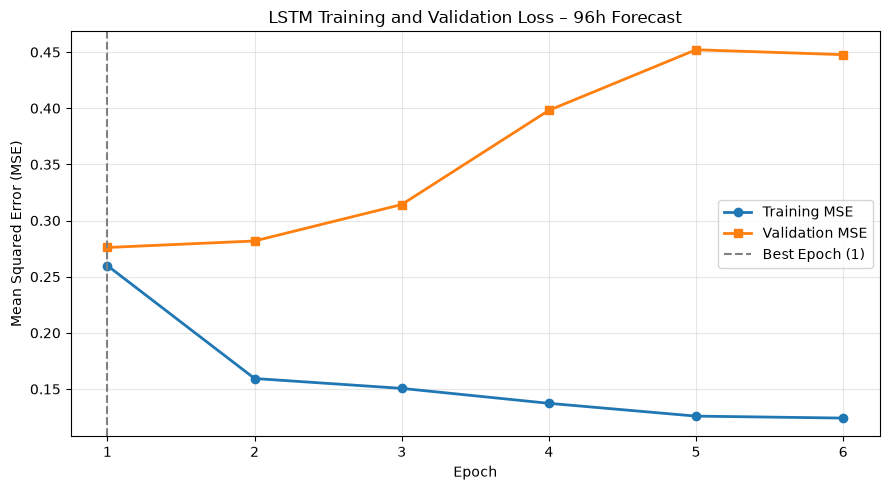

Figure saved successfully!
File: figures/LSTM_96h_Loss_Curve.png


In [10]:

import matplotlib.pyplot as plt
from pathlib import Path

# Create figures directory
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Epoch numbers
epochs = range(1, len(train_losses) + 1)

# Create figure
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Training MSE"
)

plt.plot(
    epochs,
    val_losses,
    marker="s",
    linewidth=2,
    label="Validation MSE"
)

# Highlight best epoch
plt.axvline(
    x=best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("LSTM Training and Validation Loss – 96h Forecast")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save high-resolution figure
figure_path = figures_dir / "LSTM_96h_Loss_Curve.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")
print("File:", figure_path)


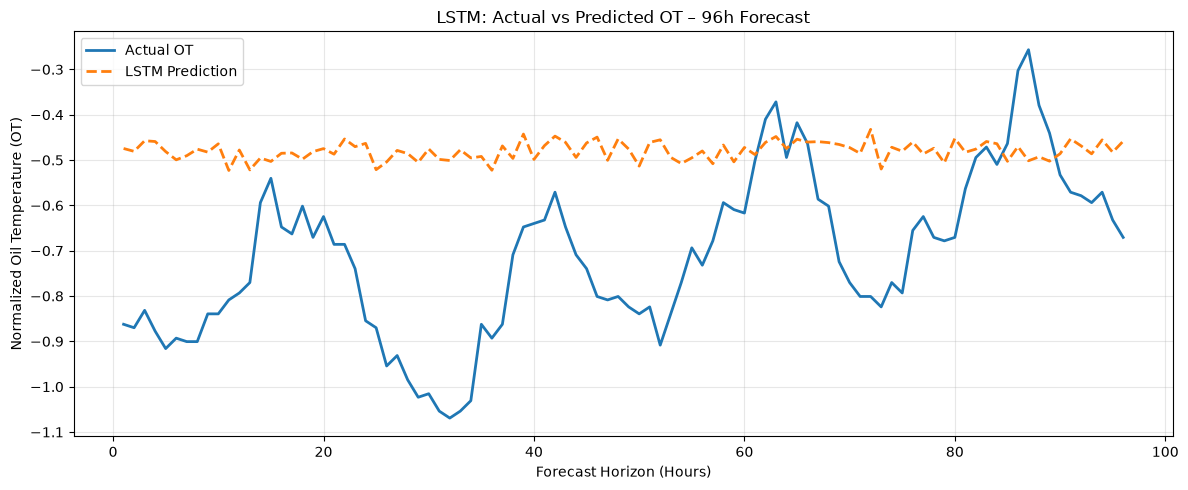

Sample MSE: 0.083346
Sample MAE: 0.248133
Figure saved: figures/LSTM_96h_Actual_vs_Predicted.png


In [11]:

# Step 11: Visualize LSTM predictions (96-hour horizon)

import matplotlib.pyplot as plt
import numpy as np

# Use the best restored LSTM model
model.eval()

# Select the first test sequence
sample_idx = 0

# Prepare input
sample_X = X_test[sample_idx:sample_idx+1].to(device)

# Actual future OT values
actual = y_test[sample_idx].cpu().numpy()

# Generate prediction
with torch.no_grad():
    predicted = model(sample_X).cpu().numpy().flatten()

# Forecast time steps
hours = np.arange(1, PRED_LEN + 1)

# Create figure
plt.figure(figsize=(12, 5))

plt.plot(
    hours,
    actual,
    label="Actual OT",
    linewidth=2
)

plt.plot(
    hours,
    predicted,
    label="LSTM Prediction",
    linewidth=2,
    linestyle="--"
)

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("Normalized Oil Temperature (OT)")
plt.title("LSTM: Actual vs Predicted OT – 96h Forecast")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure
figure_path = figures_dir / "LSTM_96h_Actual_vs_Predicted.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calculate error for this sample
sample_mse = np.mean((actual - predicted) ** 2)
sample_mae = np.mean(np.abs(actual - predicted))

print(f"Sample MSE: {sample_mse:.6f}")
print(f"Sample MAE: {sample_mae:.6f}")
print(f"Figure saved: {figure_path}")


In [12]:

# Step 12: Initialize a simpler LSTM configuration

# Set seed before model initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Tuned configuration
TUNED_HIDDEN_SIZE = 32
TUNED_NUM_LAYERS = 1
TUNED_DROPOUT = 0.0
TUNED_LEARNING_RATE = 0.0005

# Create a separate model
tuned_model = LSTMForecaster(
    input_size=INPUT_SIZE,
    hidden_size=TUNED_HIDDEN_SIZE,
    num_layers=TUNED_NUM_LAYERS,
    dropout=TUNED_DROPOUT,
    pred_len=96
).to(device)

# Optimizer
tuned_optimizer = optim.Adam(
    tuned_model.parameters(),
    lr=TUNED_LEARNING_RATE
)

# Count parameters
tuned_params = sum(
    p.numel()
    for p in tuned_model.parameters()
    if p.requires_grad
)

print("===== Simpler LSTM Configuration =====")
print(tuned_model)
print(f"\nTrainable parameters: {tuned_params:,}")
print(f"Learning rate: {TUNED_LEARNING_RATE}")
print(f"Hidden size: {TUNED_HIDDEN_SIZE}")
print(f"LSTM layers: {TUNED_NUM_LAYERS}")
print(f"Dropout: {TUNED_DROPOUT}")

# Verify output dimensions
tuned_model.eval()

with torch.no_grad():
    test_output = tuned_model(
        torch.randn(32, 96, 7, device=device)
    )

print("\nOutput shape:", tuple(test_output.shape))
print("Simpler LSTM initialized successfully!")


===== Simpler LSTM Configuration =====
LSTMForecaster(
  (lstm): LSTM(7, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=96, bias=True)
)

Trainable parameters: 8,416
Learning rate: 0.0005
Hidden size: 32
LSTM layers: 1
Dropout: 0.0

Output shape: (32, 96)
Simpler LSTM initialized successfully!


In [13]:

# Step 13: Train simpler LSTM configuration

import time
from pathlib import Path

tuned_train_losses = []
tuned_val_losses = []

tuned_best_val_loss = float("inf")
tuned_best_epoch = 0
tuned_patience_counter = 0

# Separate checkpoint to preserve initial model
tuned_checkpoint_path = (
    Path("checkpoints") / "LSTM_96h_simple_best.pt"
)

tuned_checkpoint_path.parent.mkdir(
    parents=True, exist_ok=True
)

# Start timer
if device.type == "cuda":
    torch.cuda.synchronize()

tuned_start_time = time.perf_counter()

for epoch in range(MAX_EPOCHS):

    # ----- Training -----
    tuned_model.train()
    train_loss_sum = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        tuned_optimizer.zero_grad()

        predictions = tuned_model(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        tuned_optimizer.step()

        train_loss_sum += loss.item() * batch_X.size(0)

    avg_train_loss = train_loss_sum / len(train_dataset)

    # ----- Validation -----
    tuned_model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = tuned_model(batch_X)
            loss = criterion(predictions, batch_y)

            val_loss_sum += loss.item() * batch_X.size(0)

    avg_val_loss = val_loss_sum / len(val_dataset)

    tuned_train_losses.append(avg_train_loss)
    tuned_val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {avg_train_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f}",
        flush=True
    )

    # ----- Early Stopping -----
    if avg_val_loss < tuned_best_val_loss:

        tuned_best_val_loss = avg_val_loss
        tuned_best_epoch = epoch + 1
        tuned_patience_counter = 0

        torch.save(
            tuned_model.state_dict(),
            tuned_checkpoint_path
        )

    else:
        tuned_patience_counter += 1

        if tuned_patience_counter >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Stop timer
if device.type == "cuda":
    torch.cuda.synchronize()

tuned_training_time = (
    time.perf_counter() - tuned_start_time
)

# Restore best weights
tuned_model.load_state_dict(
    torch.load(
        tuned_checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

print("\n===== Simpler LSTM Training Summary =====")
print(f"Best epoch: {tuned_best_epoch}")
print(f"Best validation MSE: {tuned_best_val_loss:.6f}")
print(f"Training time: {tuned_training_time:.2f} seconds")
print(f"Checkpoint: {tuned_checkpoint_path}")

print("\n===== Validation Comparison =====")
print(f"Initial LSTM: {best_val_loss:.6f}")
print(f"Simple LSTM:  {tuned_best_val_loss:.6f}")

if tuned_best_val_loss < best_val_loss:
    print("Simpler LSTM improved validation MSE!")
else:
    print("Initial LSTM has better validation MSE.")


Epoch 01/30 | Train MSE: 0.439082 | Val MSE: 0.260937
Epoch 02/30 | Train MSE: 0.167539 | Val MSE: 0.287283
Epoch 03/30 | Train MSE: 0.162388 | Val MSE: 0.311915
Epoch 04/30 | Train MSE: 0.151371 | Val MSE: 0.304915
Epoch 05/30 | Train MSE: 0.146747 | Val MSE: 0.303491
Epoch 06/30 | Train MSE: 0.144286 | Val MSE: 0.293370

Early stopping triggered.

===== Simpler LSTM Training Summary =====
Best epoch: 1
Best validation MSE: 0.260937
Training time: 8.81 seconds
Checkpoint: checkpoints/LSTM_96h_simple_best.pt

===== Validation Comparison =====
Initial LSTM: 0.276028
Simple LSTM:  0.260937
Simpler LSTM improved validation MSE!


In [14]:

# Step 14: Save LSTM validation comparison

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Model": "LSTM",
        "Configuration": "Initial",
        "Horizon": 96,
        "Hidden_Size": 64,
        "Layers": 2,
        "Dropout": 0.1,
        "Learning_Rate": 0.001,
        "Parameters": total_params,
        "Best_Epoch": best_epoch,
        "Validation_MSE": best_val_loss,
        "Training_Time_Seconds": training_time
    },
    {
        "Model": "LSTM",
        "Configuration": "Simple",
        "Horizon": 96,
        "Hidden_Size": TUNED_HIDDEN_SIZE,
        "Layers": TUNED_NUM_LAYERS,
        "Dropout": TUNED_DROPOUT,
        "Learning_Rate": TUNED_LEARNING_RATE,
        "Parameters": tuned_params,
        "Best_Epoch": tuned_best_epoch,
        "Validation_MSE": tuned_best_val_loss,
        "Training_Time_Seconds": tuned_training_time
    }
])

comparison_path = (
    results_dir / "LSTM_96h_Validation_Comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("Validation comparison saved successfully!")
print("File:", comparison_path)

display(comparison)


Validation comparison saved successfully!
File: results/LSTM_96h_Validation_Comparison.csv


,Model,Configuration,Horizon,Hidden_Size,Layers,Dropout,Learning_Rate,Parameters,Best_Epoch,Validation_MSE,Training_Time_Seconds
0,LSTM,Initial,96,64,2,0.1,0.0010,58208,1,0.276028,11.543566
1,LSTM,Simple,96,32,1,0.0,0.0005,8416,1,0.260937,8.812514


In [15]:

# Step 15: Prepare LSTM for 336-hour forecasting

# Load preprocessed 336-hour dataset
data_336 = torch.load(
    "processed_data/ETTh1_336h_preprocessed.pt",
    map_location="cpu",
    weights_only=True
)

# Extract tensors
X_train_336 = data_336["X_train"]
y_train_336 = data_336["y_train"]

X_val_336 = data_336["X_val"]
y_val_336 = data_336["y_val"]

X_test_336 = data_336["X_test"]
y_test_336 = data_336["y_test"]

# Verify dataset dimensions and target
assert X_train_336.shape[1:] == (96, 7)
assert y_train_336.shape[1] == 336
assert data_336["target_index"] == 6

# Create DataLoaders
train_loader_336 = DataLoader(
    TensorDataset(X_train_336, y_train_336),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_336 = DataLoader(
    TensorDataset(X_val_336, y_val_336),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_336 = DataLoader(
    TensorDataset(X_test_336, y_test_336),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Set seed before model initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Initialize selected simpler LSTM
model_336 = LSTMForecaster(
    input_size=7,
    hidden_size=TUNED_HIDDEN_SIZE,
    num_layers=TUNED_NUM_LAYERS,
    dropout=TUNED_DROPOUT,
    pred_len=336
).to(device)

# Configure optimizer
optimizer_336 = optim.Adam(
    model_336.parameters(),
    lr=TUNED_LEARNING_RATE
)

# Count trainable parameters
params_336 = sum(
    p.numel()
    for p in model_336.parameters()
    if p.requires_grad
)

# Verify forward pass
model_336.eval()

with torch.no_grad():
    dummy_output_336 = model_336(
        torch.randn(32, 96, 7, device=device)
    )

assert dummy_output_336.shape == (32, 336)

print("===== LSTM 336h Configuration =====")
print("Training samples:", len(X_train_336))
print("Validation samples:", len(X_val_336))
print("Test samples:", len(X_test_336))

print("\nInput shape:", tuple(X_train_336.shape))
print("Target shape:", tuple(y_train_336.shape))
print("Model output shape:", tuple(dummy_output_336.shape))

print("\nTrainable parameters:", params_336)
print("Learning rate:", TUNED_LEARNING_RATE)
print("Device:", device)

print("\n336-hour LSTM ready for training!")


===== LSTM 336h Configuration =====
Training samples: 8209
Validation samples: 2545
Test samples: 2545

Input shape: (8209, 96, 7)
Target shape: (8209, 336)
Model output shape: (32, 336)

Trainable parameters: 16336
Learning rate: 0.0005
Device: cuda:0

336-hour LSTM ready for training!


In [16]:

# Step 16: Train LSTM for 336-hour forecasting

import time
from pathlib import Path

# Reset training history and early stopping
train_losses_336 = []
val_losses_336 = []

best_val_loss_336 = float("inf")
best_epoch_336 = 0
patience_counter_336 = 0

# Separate checkpoint for 336-hour model
checkpoint_path_336 = (
    Path("checkpoints") / "LSTM_336h_simple_best.pt"
)

checkpoint_path_336.parent.mkdir(
    parents=True, exist_ok=True
)

# Start timer
if device.type == "cuda":
    torch.cuda.synchronize()

start_time_336 = time.perf_counter()

for epoch in range(MAX_EPOCHS):

    # ----- Training -----
    model_336.train()
    train_loss_sum = 0.0

    for batch_X, batch_y in train_loader_336:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_336.zero_grad()

        predictions = model_336(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer_336.step()

        train_loss_sum += loss.item() * batch_X.size(0)

    avg_train_loss = train_loss_sum / len(X_train_336)

    # ----- Validation -----
    model_336.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for batch_X, batch_y in val_loader_336:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model_336(batch_X)
            loss = criterion(predictions, batch_y)

            val_loss_sum += loss.item() * batch_X.size(0)

    avg_val_loss = val_loss_sum / len(X_val_336)

    train_losses_336.append(avg_train_loss)
    val_losses_336.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {avg_train_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f}",
        flush=True
    )

    # ----- Early Stopping -----
    if avg_val_loss < best_val_loss_336:

        best_val_loss_336 = avg_val_loss
        best_epoch_336 = epoch + 1
        patience_counter_336 = 0

        torch.save(
            model_336.state_dict(),
            checkpoint_path_336
        )

    else:
        patience_counter_336 += 1

        if patience_counter_336 >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Stop timer
if device.type == "cuda":
    torch.cuda.synchronize()

training_time_336 = (
    time.perf_counter() - start_time_336
)

# Restore best checkpoint
model_336.load_state_dict(
    torch.load(
        checkpoint_path_336,
        map_location=device,
        weights_only=True
    )
)

print("\n===== LSTM 336h Training Summary =====")
print(f"Best epoch: {best_epoch_336}")
print(f"Best validation MSE: {best_val_loss_336:.6f}")
print(f"Training time: {training_time_336:.2f} seconds")
print(f"Trainable parameters: {params_336:,}")
print(f"Checkpoint: {checkpoint_path_336}")


Epoch 01/30 | Train MSE: 0.472342 | Val MSE: 0.336442
Epoch 02/30 | Train MSE: 0.188900 | Val MSE: 0.332328
Epoch 03/30 | Train MSE: 0.175698 | Val MSE: 0.283172
Epoch 04/30 | Train MSE: 0.171298 | Val MSE: 0.315686
Epoch 05/30 | Train MSE: 0.164834 | Val MSE: 0.323864
Epoch 06/30 | Train MSE: 0.161307 | Val MSE: 0.341063
Epoch 07/30 | Train MSE: 0.160066 | Val MSE: 0.294816
Epoch 08/30 | Train MSE: 0.156185 | Val MSE: 0.308595

Early stopping triggered.

===== LSTM 336h Training Summary =====
Best epoch: 3
Best validation MSE: 0.283172
Training time: 11.48 seconds
Trainable parameters: 16,336
Checkpoint: checkpoints/LSTM_336h_simple_best.pt


In [17]:

# Step 17: Evaluate 336-hour LSTM on test data

model_336.eval()

test_mse_sum_336 = 0.0
test_mae_sum_336 = 0.0

with torch.no_grad():

    for batch_X, batch_y in test_loader_336:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        predictions = model_336(batch_X)

        test_mse_sum_336 += torch.sum(
            (predictions - batch_y) ** 2
        ).item()

        test_mae_sum_336 += torch.sum(
            torch.abs(predictions - batch_y)
        ).item()

# Total predicted OT values
total_predictions_336 = (
    len(X_test_336) * 336
)

test_mse_336 = (
    test_mse_sum_336 / total_predictions_336
)

test_mae_336 = (
    test_mae_sum_336 / total_predictions_336
)

print("===== LSTM Test Results (336 Hours) =====")
print(f"Test MSE: {test_mse_336:.6f}")
print(f"Test MAE: {test_mae_336:.6f}")
print(f"Best Validation MSE: {best_val_loss_336:.6f}")
print(f"Best Epoch: {best_epoch_336}")
print(f"Training Time: {training_time_336:.2f} seconds")
print(f"Trainable Parameters: {params_336:,}")


===== LSTM Test Results (336 Hours) =====
Test MSE: 0.612728
Test MAE: 0.737606
Best Validation MSE: 0.283172
Best Epoch: 3
Training Time: 11.48 seconds
Trainable Parameters: 16,336


In [18]:

# Step 18: Save LSTM 336-hour experimental results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

lstm_336_results = pd.DataFrame([{
    "Model": "LSTM",
    "Experiment": "Simple",
    "Input_Length": 96,
    "Prediction_Length": 336,
    "Hidden_Size": TUNED_HIDDEN_SIZE,
    "LSTM_Layers": TUNED_NUM_LAYERS,
    "Dropout": TUNED_DROPOUT,
    "Learning_Rate": TUNED_LEARNING_RATE,
    "Batch_Size": BATCH_SIZE,
    "Seed": SEED,
    "Best_Epoch": best_epoch_336,
    "Validation_MSE": best_val_loss_336,
    "Test_MSE": test_mse_336,
    "Test_MAE": test_mae_336,
    "Training_Time_Seconds": training_time_336,
    "Trainable_Parameters": params_336
}])

results_path_336 = (
    results_dir / "LSTM_336h_simple_results.csv"
)

lstm_336_results.to_csv(
    results_path_336,
    index=False
)

print("336-hour LSTM results saved successfully!")
print("File:", results_path_336)

display(lstm_336_results.T)


336-hour LSTM results saved successfully!
File: results/LSTM_336h_simple_results.csv


,0
Model,LSTM
Experiment,Simple
Input_Length,96
Prediction_Length,336
Hidden_Size,32
LSTM_Layers,1
Dropout,0.0
Learning_Rate,0.0005
Batch_Size,32
Seed,42


In [19]:

# Step 19: Prepare LSTM for 720-hour forecasting

# Load preprocessed dataset
data_720 = torch.load(
    "processed_data/ETTh1_720h_preprocessed.pt",
    map_location="cpu",
    weights_only=True
)

# Extract tensors
X_train_720 = data_720["X_train"]
y_train_720 = data_720["y_train"]

X_val_720 = data_720["X_val"]
y_val_720 = data_720["y_val"]

X_test_720 = data_720["X_test"]
y_test_720 = data_720["y_test"]

# Verify dataset dimensions
assert X_train_720.shape[1:] == (96, 7)
assert y_train_720.shape[1] == 720
assert data_720["input_len"] == 96
assert data_720["pred_len"] == 720
assert data_720["target_index"] == 6

# Create DataLoaders
train_loader_720 = DataLoader(
    TensorDataset(X_train_720, y_train_720),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_720 = DataLoader(
    TensorDataset(X_val_720, y_val_720),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_720 = DataLoader(
    TensorDataset(X_test_720, y_test_720),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Set random seed before model initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Initialize selected simpler LSTM
model_720 = LSTMForecaster(
    input_size=7,
    hidden_size=TUNED_HIDDEN_SIZE,
    num_layers=TUNED_NUM_LAYERS,
    dropout=TUNED_DROPOUT,
    pred_len=720
).to(device)

# Configure optimizer
optimizer_720 = optim.Adam(
    model_720.parameters(),
    lr=TUNED_LEARNING_RATE
)

# Count trainable parameters
params_720 = sum(
    p.numel()
    for p in model_720.parameters()
    if p.requires_grad
)

# Verify forward pass
model_720.eval()

with torch.no_grad():
    dummy_output_720 = model_720(
        torch.randn(32, 96, 7, device=device)
    )

assert dummy_output_720.shape == (32, 720)

print("===== LSTM 720h Configuration =====")
print("Training samples:", len(X_train_720))
print("Validation samples:", len(X_val_720))
print("Test samples:", len(X_test_720))

print("\nInput shape:", tuple(X_train_720.shape))
print("Target shape:", tuple(y_train_720.shape))
print("Model output shape:", tuple(dummy_output_720.shape))

print("\nTrainable parameters:", params_720)
print("Learning rate:", TUNED_LEARNING_RATE)
print("Device:", device)

print("\n720-hour LSTM ready for training!")


===== LSTM 720h Configuration =====
Training samples: 7825
Validation samples: 2161
Test samples: 2161

Input shape: (7825, 96, 7)
Target shape: (7825, 720)
Model output shape: (32, 720)

Trainable parameters: 29008
Learning rate: 0.0005
Device: cuda:0

720-hour LSTM ready for training!


In [20]:

# Step 20: Train LSTM for 720-hour forecasting

import time
from pathlib import Path

# Reset training history and early stopping
train_losses_720 = []
val_losses_720 = []

best_val_loss_720 = float("inf")
best_epoch_720 = 0
patience_counter_720 = 0

# Separate checkpoint for 720-hour model
checkpoint_path_720 = (
    Path("checkpoints") / "LSTM_720h_simple_best.pt"
)

checkpoint_path_720.parent.mkdir(
    parents=True, exist_ok=True
)

# Start timer
if device.type == "cuda":
    torch.cuda.synchronize()

start_time_720 = time.perf_counter()

for epoch in range(MAX_EPOCHS):

    # ----- Training -----
    model_720.train()
    train_loss_sum = 0.0

    for batch_X, batch_y in train_loader_720:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_720.zero_grad()

        predictions = model_720(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer_720.step()

        train_loss_sum += loss.item() * batch_X.size(0)

    avg_train_loss = train_loss_sum / len(X_train_720)

    # ----- Validation -----
    model_720.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for batch_X, batch_y in val_loader_720:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model_720(batch_X)
            loss = criterion(predictions, batch_y)

            val_loss_sum += loss.item() * batch_X.size(0)

    avg_val_loss = val_loss_sum / len(X_val_720)

    train_losses_720.append(avg_train_loss)
    val_losses_720.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {avg_train_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f}",
        flush=True
    )

    # ----- Early Stopping -----
    if avg_val_loss < best_val_loss_720:

        best_val_loss_720 = avg_val_loss
        best_epoch_720 = epoch + 1
        patience_counter_720 = 0

        torch.save(
            model_720.state_dict(),
            checkpoint_path_720
        )

    else:
        patience_counter_720 += 1

        if patience_counter_720 >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Stop timer
if device.type == "cuda":
    torch.cuda.synchronize()

training_time_720 = (
    time.perf_counter() - start_time_720
)

# Restore best checkpoint
model_720.load_state_dict(
    torch.load(
        checkpoint_path_720,
        map_location=device,
        weights_only=True
    )
)

print("\n===== LSTM 720h Training Summary =====")
print(f"Best epoch: {best_epoch_720}")
print(f"Best validation MSE: {best_val_loss_720:.6f}")
print(f"Training time: {training_time_720:.2f} seconds")
print(f"Trainable parameters: {params_720:,}")
print(f"Checkpoint: {checkpoint_path_720}")


Epoch 01/30 | Train MSE: 0.473845 | Val MSE: 0.386906
Epoch 02/30 | Train MSE: 0.207117 | Val MSE: 0.373867
Epoch 03/30 | Train MSE: 0.187121 | Val MSE: 0.373152
Epoch 04/30 | Train MSE: 0.178586 | Val MSE: 0.395279
Epoch 05/30 | Train MSE: 0.172964 | Val MSE: 0.417241
Epoch 06/30 | Train MSE: 0.169471 | Val MSE: 0.426018
Epoch 07/30 | Train MSE: 0.164626 | Val MSE: 0.395337
Epoch 08/30 | Train MSE: 0.164435 | Val MSE: 0.397071

Early stopping triggered.

===== LSTM 720h Training Summary =====
Best epoch: 3
Best validation MSE: 0.373152
Training time: 11.09 seconds
Trainable parameters: 29,008
Checkpoint: checkpoints/LSTM_720h_simple_best.pt


In [21]:

# Step 21: Evaluate 720-hour LSTM on test data

model_720.eval()

test_mse_sum_720 = 0.0
test_mae_sum_720 = 0.0

with torch.no_grad():

    for batch_X, batch_y in test_loader_720:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        predictions = model_720(batch_X)

        test_mse_sum_720 += torch.sum(
            (predictions - batch_y) ** 2
        ).item()

        test_mae_sum_720 += torch.sum(
            torch.abs(predictions - batch_y)
        ).item()

# Total number of predicted OT values
total_predictions_720 = (
    len(X_test_720) * 720
)

test_mse_720 = (
    test_mse_sum_720 / total_predictions_720
)

test_mae_720 = (
    test_mae_sum_720 / total_predictions_720
)

print("===== LSTM Test Results (720 Hours) =====")
print(f"Test MSE: {test_mse_720:.6f}")
print(f"Test MAE: {test_mae_720:.6f}")
print(f"Best Validation MSE: {best_val_loss_720:.6f}")
print(f"Best Epoch: {best_epoch_720}")
print(f"Training Time: {training_time_720:.2f} seconds")
print(f"Trainable Parameters: {params_720:,}")


===== LSTM Test Results (720 Hours) =====
Test MSE: 0.857829
Test MAE: 0.876643
Best Validation MSE: 0.373152
Best Epoch: 3
Training Time: 11.09 seconds
Trainable Parameters: 29,008


In [22]:

# Step 22: Save LSTM 720-hour experimental results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

lstm_720_results = pd.DataFrame([{
    "Model": "LSTM",
    "Experiment": "Simple",
    "Input_Length": 96,
    "Prediction_Length": 720,
    "Hidden_Size": TUNED_HIDDEN_SIZE,
    "LSTM_Layers": TUNED_NUM_LAYERS,
    "Dropout": TUNED_DROPOUT,
    "Learning_Rate": TUNED_LEARNING_RATE,
    "Batch_Size": BATCH_SIZE,
    "Seed": SEED,
    "Best_Epoch": best_epoch_720,
    "Validation_MSE": best_val_loss_720,
    "Test_MSE": test_mse_720,
    "Test_MAE": test_mae_720,
    "Training_Time_Seconds": training_time_720,
    "Trainable_Parameters": params_720
}])

results_path_720 = (
    results_dir / "LSTM_720h_simple_results.csv"
)

lstm_720_results.to_csv(
    results_path_720,
    index=False
)

print("720-hour LSTM results saved successfully!")
print("File:", results_path_720)

display(lstm_720_results.T)


720-hour LSTM results saved successfully!
File: results/LSTM_720h_simple_results.csv


,0
Model,LSTM
Experiment,Simple
Input_Length,96
Prediction_Length,720
Hidden_Size,32
LSTM_Layers,1
Dropout,0.0
Learning_Rate,0.0005
Batch_Size,32
Seed,42


In [23]:

# Step 23: Evaluate the selected simple 96-hour LSTM

# Load the best saved simple-model checkpoint
tuned_model.load_state_dict(
    torch.load(
        "checkpoints/LSTM_96h_simple_best.pt",
        map_location=device,
        weights_only=True
    )
)

tuned_model.eval()

test_mse_sum_96 = 0.0
test_mae_sum_96 = 0.0
total_predictions_96 = 0

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        predictions = tuned_model(batch_X)

        test_mse_sum_96 += torch.sum(
            (predictions - batch_y) ** 2
        ).item()

        test_mae_sum_96 += torch.sum(
            torch.abs(predictions - batch_y)
        ).item()

        total_predictions_96 += batch_y.numel()

# Calculate average errors
test_mse_96_simple = (
    test_mse_sum_96 / total_predictions_96
)

test_mae_96_simple = (
    test_mae_sum_96 / total_predictions_96
)

print("===== Simple LSTM Test Results (96 Hours) =====")
print(f"Test MSE: {test_mse_96_simple:.6f}")
print(f"Test MAE: {test_mae_96_simple:.6f}")
print(f"Best Validation MSE: {tuned_best_val_loss:.6f}")
print(f"Best Epoch: {tuned_best_epoch}")
print(f"Training Time: {tuned_training_time:.2f} seconds")
print(f"Trainable Parameters: {tuned_params:,}")


===== Simple LSTM Test Results (96 Hours) =====
Test MSE: 0.501855
Test MAE: 0.645748
Best Validation MSE: 0.260937
Best Epoch: 1
Training Time: 8.81 seconds
Trainable Parameters: 8,416


In [24]:

# Step 24: Save selected 96-hour LSTM results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

lstm_96_simple_results = pd.DataFrame([{
    "Model": "LSTM",
    "Experiment": "Simple",
    "Input_Length": 96,
    "Prediction_Length": 96,
    "Hidden_Size": TUNED_HIDDEN_SIZE,
    "LSTM_Layers": TUNED_NUM_LAYERS,
    "Dropout": TUNED_DROPOUT,
    "Learning_Rate": TUNED_LEARNING_RATE,
    "Batch_Size": BATCH_SIZE,
    "Seed": SEED,
    "Best_Epoch": tuned_best_epoch,
    "Validation_MSE": tuned_best_val_loss,
    "Test_MSE": test_mse_96_simple,
    "Test_MAE": test_mae_96_simple,
    "Training_Time_Seconds": tuned_training_time,
    "Trainable_Parameters": tuned_params
}])

results_path_96_simple = (
    results_dir / "LSTM_96h_simple_results.csv"
)

lstm_96_simple_results.to_csv(
    results_path_96_simple,
    index=False
)

print("96-hour simple LSTM results saved successfully!")
print("File:", results_path_96_simple)

display(lstm_96_simple_results.T)


96-hour simple LSTM results saved successfully!
File: results/LSTM_96h_simple_results.csv


,0
Model,LSTM
Experiment,Simple
Input_Length,96
Prediction_Length,96
Hidden_Size,32
LSTM_Layers,1
Dropout,0.0
Learning_Rate,0.0005
Batch_Size,32
Seed,42


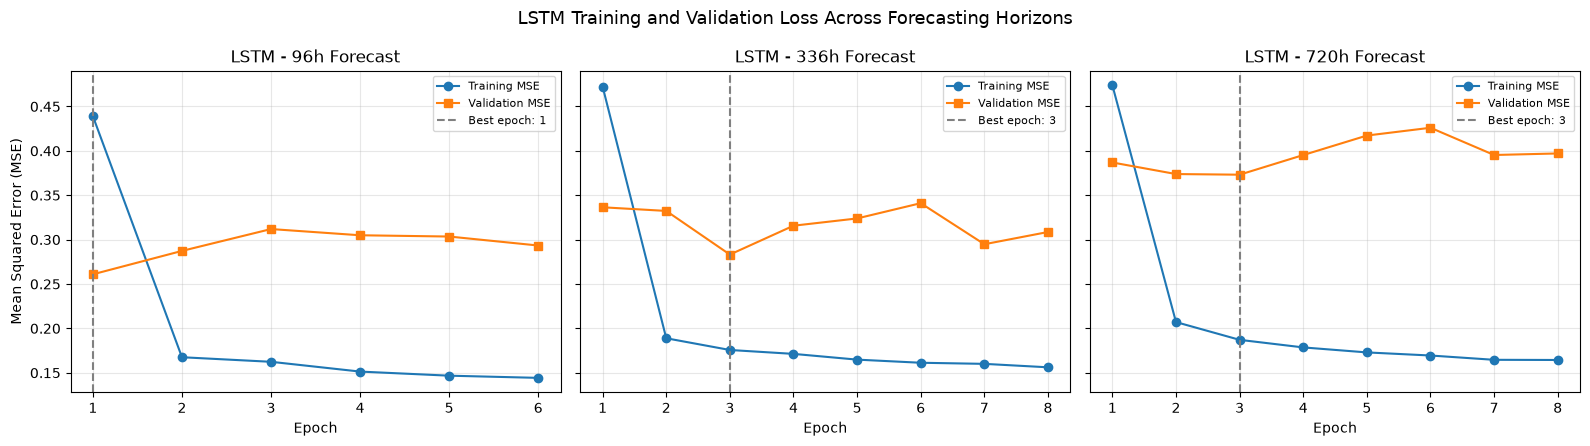

Figure saved successfully!
File: figures/LSTM_All_Horizons_Loss_Curves.png


In [25]:

# Step 25: Plot training and validation loss curves
# for all three forecasting horizons

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

loss_histories = {
    96: (tuned_train_losses, tuned_val_losses),
    336: (train_losses_336, val_losses_336),
    720: (train_losses_720, val_losses_720)
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharey=True
)

for ax, (horizon, (train_history, val_history)) in zip(
    axes, loss_histories.items()
):

    epochs = range(1, len(train_history) + 1)

    ax.plot(
        epochs,
        train_history,
        marker="o",
        label="Training MSE"
    )

    ax.plot(
        epochs,
        val_history,
        marker="s",
        label="Validation MSE"
    )

    best_epoch = min(
        range(len(val_history)),
        key=lambda i: val_history[i]
    ) + 1

    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label=f"Best epoch: {best_epoch}"
    )

    ax.set_title(f"LSTM - {horizon}h Forecast")
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Mean Squared Error (MSE)")

fig.suptitle(
    "LSTM Training and Validation Loss Across Forecasting Horizons",
    fontsize=13
)

plt.tight_layout()

figure_path = (
    figures_dir / "LSTM_All_Horizons_Loss_Curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")
print("File:", figure_path)


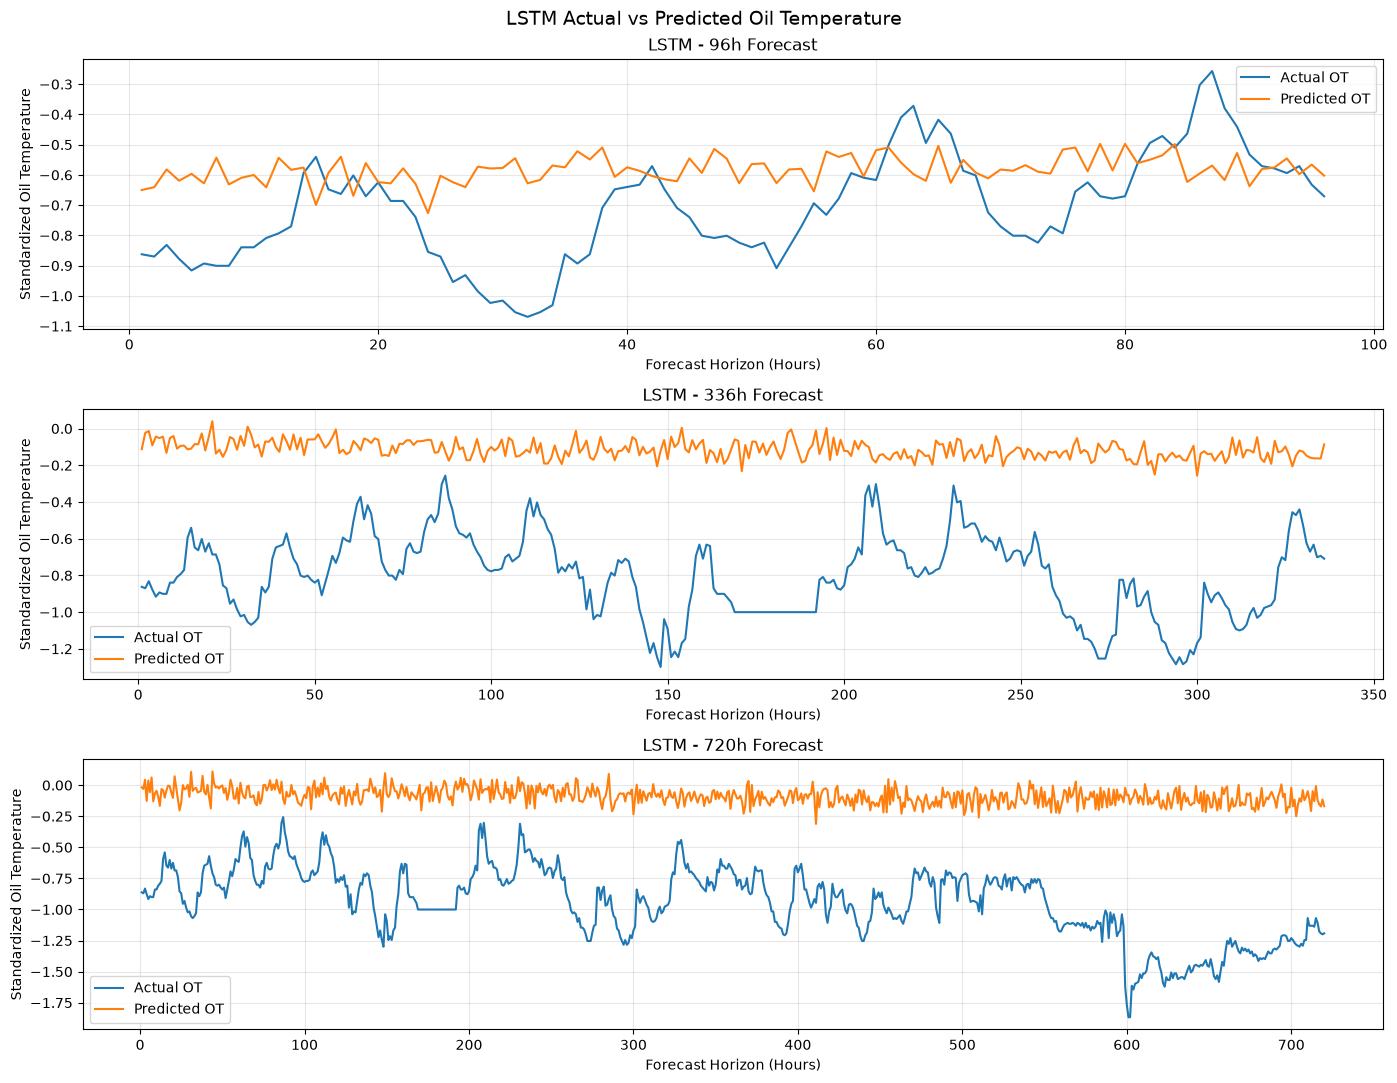

Figure saved successfully!
File: figures/LSTM_All_Horizons_Actual_vs_Predicted.png


In [26]:

# Step 26: Plot actual vs predicted OT for all horizons

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

forecast_experiments = [
    (96, tuned_model, X_test, y_test),
    (336, model_336, X_test_336, y_test_336),
    (720, model_720, X_test_720, y_test_720)
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11)
)

for ax, (horizon, forecast_model, X, y) in zip(
    axes, forecast_experiments
):

    forecast_model.eval()

    # First test window
    sample_X = X[0:1].to(device)

    with torch.no_grad():
        predicted = (
            forecast_model(sample_X)
            .cpu()
            .numpy()
            .flatten()
        )

    actual = y[0].cpu().numpy().flatten()

    forecast_hours = range(1, horizon + 1)

    ax.plot(
        forecast_hours,
        actual,
        label="Actual OT",
        linewidth=1.5
    )

    ax.plot(
        forecast_hours,
        predicted,
        label="Predicted OT",
        linewidth=1.5
    )

    ax.set_title(f"LSTM - {horizon}h Forecast")
    ax.set_xlabel("Forecast Horizon (Hours)")
    ax.set_ylabel("Standardized Oil Temperature")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "LSTM Actual vs Predicted Oil Temperature",
    fontsize=14
)

plt.tight_layout()

figure_path = (
    figures_dir / "LSTM_All_Horizons_Actual_vs_Predicted.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")
print("File:", figure_path)


In [27]:

# Step 27: Consolidate LSTM results across all horizons

import pandas as pd
from pathlib import Path

results_dir = Path("results")

# Read final selected LSTM experiment results
result_files = [
    results_dir / "LSTM_96h_simple_results.csv",
    results_dir / "LSTM_336h_simple_results.csv",
    results_dir / "LSTM_720h_simple_results.csv"
]

# Combine results into one DataFrame
lstm_all_results = pd.concat(
    [pd.read_csv(file) for file in result_files],
    ignore_index=True
)

# Sort by prediction horizon
lstm_all_results = lstm_all_results.sort_values(
    "Prediction_Length"
).reset_index(drop=True)

# Save consolidated results
consolidated_path = (
    results_dir / "LSTM_All_Horizons_Results.csv"
)

lstm_all_results.to_csv(
    consolidated_path,
    index=False
)

# Display important columns
summary_columns = [
    "Model",
    "Prediction_Length",
    "Validation_MSE",
    "Test_MSE",
    "Test_MAE",
    "Best_Epoch",
    "Training_Time_Seconds",
    "Trainable_Parameters"
]

print("===== LSTM Results Across All Horizons =====")

display(
    lstm_all_results[summary_columns].round(6)
)

print("\nConsolidated results saved successfully!")
print("File:", consolidated_path)


===== LSTM Results Across All Horizons =====


,Model,Prediction_Length,Validation_MSE,Test_MSE,Test_MAE,Best_Epoch,Training_Time_Seconds,Trainable_Parameters
0,LSTM,96,0.260937,0.501855,0.645748,1,8.812514,8416
1,LSTM,336,0.283172,0.612728,0.737606,3,11.479456,16336
2,LSTM,720,0.373152,0.857829,0.876643,3,11.089589,29008



Consolidated results saved successfully!
File: results/LSTM_All_Horizons_Results.csv


In [28]:

# Step 28: Verify saved LSTM experiment files

from pathlib import Path

required_files = [
    # Notebook
    "06_ETTh1_LSTM.ipynb",

    # Model checkpoints
    "checkpoints/LSTM_96h_best.pt",
    "checkpoints/LSTM_96h_simple_best.pt",
    "checkpoints/LSTM_336h_simple_best.pt",
    "checkpoints/LSTM_720h_simple_best.pt",

    # Experimental results
    "results/LSTM_96h_initial_results.csv",
    "results/LSTM_96h_Validation_Comparison.csv",
    "results/LSTM_96h_simple_results.csv",
    "results/LSTM_336h_simple_results.csv",
    "results/LSTM_720h_simple_results.csv",
    "results/LSTM_All_Horizons_Results.csv",

    # Figures
    "figures/LSTM_96h_Loss_Curve.png",
    "figures/LSTM_96h_Actual_vs_Predicted.png",
    "figures/LSTM_All_Horizons_Loss_Curves.png",
    "figures/LSTM_All_Horizons_Actual_vs_Predicted.png"
]

print("===== LSTM File Verification =====")

missing_files = []

for filename in required_files:

    path = Path(filename)

    if path.is_file():
        print(f"[OK]      {filename}")
    else:
        print(f"[MISSING] {filename}")
        missing_files.append(filename)

print("\n===== Verification Summary =====")
print("Total expected files:", len(required_files))
print("Files found:", len(required_files) - len(missing_files))
print("Missing files:", len(missing_files))

if not missing_files:
    print("\nAll LSTM experiment files are present!")
else:
    print("\nPlease check the missing files before committing.")


===== LSTM File Verification =====
[OK]      06_ETTh1_LSTM.ipynb
[OK]      checkpoints/LSTM_96h_best.pt
[OK]      checkpoints/LSTM_96h_simple_best.pt
[OK]      checkpoints/LSTM_336h_simple_best.pt
[OK]      checkpoints/LSTM_720h_simple_best.pt
[OK]      results/LSTM_96h_initial_results.csv
[OK]      results/LSTM_96h_Validation_Comparison.csv
[OK]      results/LSTM_96h_simple_results.csv
[OK]      results/LSTM_336h_simple_results.csv
[OK]      results/LSTM_720h_simple_results.csv
[OK]      results/LSTM_All_Horizons_Results.csv
[OK]      figures/LSTM_96h_Loss_Curve.png
[OK]      figures/LSTM_96h_Actual_vs_Predicted.png
[OK]      figures/LSTM_All_Horizons_Loss_Curves.png
[OK]      figures/LSTM_All_Horizons_Actual_vs_Predicted.png

===== Verification Summary =====
Total expected files: 15
Files found: 15
Missing files: 0

All LSTM experiment files are present!
